# Reverse-Engineering GPT's Decision Policy for Atomic Force Microscopy

**Greg Lorenz**

### Abstract

Can a compact visual utility predict which AFM patch GPT selects? We analyze **300 choices in three traces**, each offering 20 image patches, using handcrafted image descriptors and regularized choice models. A patch-only Fourier reward reaches **14.0% top-1 accuracy**. A model updated from **previous observed choices** reaches **36.3% top-1, 62.7% top-3, and 2.119 log loss** under the retained nested leave-one-trace-out protocol; uniform guessing gives 5.0% top-1. Ten observed choices already yield 32.7% accuracy on a common future window. Histories transferred between identical offered sets sharply reduce accuracy, while cold self-fed replay reaches only 5.3%.

The evidence supports **persistent, trace-specific visual preferences that an observer can infer from choices**. It does not establish GPT's internal reward, learning mechanism, or sequential memory. All three traces were previously explored, two share their candidate sets, and no independent final holdout exists. The strongest result requires genuine choice feedback and is **not autonomous performance**.

This notebook is the **only required submission artifact**: explanation, inline executable models, raw-data reproduction, archived controls, tables, figures, and prediction API are included here.

## 1. Problem and challenge interface

At time $t$, GPT receives a set $C_t=\{p_{t0},\ldots,p_{t19}\}$ of AFM patches and selects $y_t\in\{0,\ldots,19\}$. We seek a utility $U$ whose ranking predicts that choice:

$$\widehat y_t=\arg\max_{j}U(p_{tj},C_t,H_t),\qquad
H_t=\{(C_s,y_s):s<t\}.$$

A static reward $r(p)$ uses the image alone. A history-conditioned predictor estimates a target trace's preferences from earlier observed decisions; current and future labels are unavailable when it predicts.

The supplied challenge notebook, `llm_decision_making.ipynb`, concretely demonstrates `reward(patch) -> float`, followed by `argmax` over the 20 candidates. It invites prediction of GPT's choices but supplies no executable grader or explicit entitlement to subsequent choice feedback. Accordingly, we expose **three distinct regimes**:

| Regime | Inputs allowed at the next prediction | Meaning of its score |
|:--|:--|:--|
| Stateless reward | Current patch; candidate scoring can normalize current offers | Demonstrated challenge-compatible interface |
| Observed-history prediction | Current offers and genuinely observed earlier choices | Conditional next-choice prediction, if feedback is permitted |
| Self-fed replay | Current offers and the model's own earlier predictions | Offline replay on fixed logged offers; no actual choice feedback |

A single patch reward cannot adapt to two agents that consistently select different visual content from identical offers. The history-aware extension addresses this scientific question without assuming the evaluator will provide its inputs.

### Reproducibility and data location

Run **all cells from top to bottom** in Python 3.11 or later. Tested library versions are NumPy 2.4.6, pandas 3.0.4, SciPy 1.17.1, and Matplotlib 3.11.0. In a Jupyter environment these can be installed with:

```text
python -m pip install numpy==2.4.6 pandas==3.0.4 scipy==1.17.1 matplotlib==3.11.0 jupyter
```

Supply the organizers' original `gpt_decision_trace_0.pkl`, `gpt_decision_trace_1.pkl`, and `gpt_decision_trace_2.pkl` in a directory named `day_20_data` beside the notebook, or set `AFM_DATA_DIR` to their directory in the configuration cell below. The original download directory is also recognized when running inside this project. The eight `simulated_decision_trace_*.pkl` files are optional positive controls. These are trusted organizer pickle files; the large scan file is unnecessary because each trace contains its candidate patches.

**No project Python modules, cached predictions, external tables, or figure files are imported.** All main results and figures are rebuilt from the three raw traces. Selected earlier controls and model-selection provenance are embedded as labeled data, with optional reproduction code for the randomized control. Ordinary execution performs no model search. The notebook requires raw data to rerun; its saved results can be read without those data.

**Execution note.** The current execution environment lacks a Jupyter kernel package, so saved outputs were generated by executing every plain-Python cell, in order, in a fresh isolated Python process with figure and rich-table capture. This exercises all submitted code and raw-data dependencies; native Jupyter kernel execution was not available. The notebook contains standard nbformat-4 cells and outputs and uses no runner-specific code or magics.

In [ ]:
import copy
import hashlib
import os
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.ndimage import gaussian_filter, label
from scipy.optimize import minimize, minimize_scalar
from scipy.special import logsumexp, softmax
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Set this explicitly if automatic relative discovery does not find your data.
DATA_DIR = Path(os.environ.get('AFM_DATA_DIR', 'day_20_data'))
if not DATA_DIR.exists():
    roots = [Path.cwd(), Path.cwd().parent]
    alternatives = [r / d for r in roots for d in
                    ['day_20_data', 'drive-download-20261016T184127Z-1-001']]
    DATA_DIR = next((p for p in alternatives
                     if (p / 'gpt_decision_trace_0.pkl').exists()), DATA_DIR)
required_files = [f'gpt_decision_trace_{i}.pkl' for i in range(3)]
if not all((DATA_DIR / f).is_file() for f in required_files):
    raise FileNotFoundError('Set DATA_DIR or AFM_DATA_DIR to the three GPT trace files.')

plt.rcParams.update({'figure.dpi':120, 'savefig.dpi':150, 'font.size':10,
                     'axes.titlesize':12, 'axes.titleweight':'bold',
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'figure.facecolor':'white', 'axes.facecolor':'white'})
COLORS = ['#607D8B', '#DC8C36', '#27867B', '#9C5C88']
TRACE_COLORS = ['#3366A2', '#D07B30', '#27867B']
EPS = 1e-9
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_columns', None)
pd.DataFrame({'package':['NumPy','pandas','SciPy','Matplotlib'],
              'version':[np.__version__,pd.__version__,scipy.__version__,matplotlib.__version__]})

,package,version
0,NumPy,2.4.6
1,pandas,3.0.4
2,SciPy,1.17.1
3,Matplotlib,3.11.0


## 2. Data and exploratory analysis

The three GPT traces contain 100 consecutive decisions each. Each decision stores 20 grayscale $20\times20$ float patches, a zero-based selected index, and additional metadata. **Only image arrays enter the descriptors.** Outcome fields such as a stored selected image are never passed to inference. Labels are read separately for scoring and subsequent observation.

The audit below checks candidate count, image shape, finiteness, time keys, and label range. Hashes identify exact repeated content, including candidates in different array positions. This is an image-content audit, not a learned lookup table.

In [ ]:
def image_key(patch):
    a = np.asarray(patch)
    return hashlib.sha256(a.dtype.str.encode() + str(a.shape).encode() + a.tobytes()).hexdigest()

def load_trace(path):
    with path.open('rb') as handle:
        trace = pickle.load(handle)
    if sorted(trace) != list(range(len(trace))):
        raise ValueError('Time keys must be consecutive zero-based integers.')
    patches, choices = [], []
    for t in range(len(trace)):
        images = np.asarray(trace[t]['patches'])
        y = trace[t]['selected_candidate']
        if images.shape != (20,20,20) or not np.isfinite(images).all():
            raise ValueError('Expected 20 finite 20-by-20 patches per decision.')
        if isinstance(y,(bool,np.bool_)) or not isinstance(y,(int,np.integer)) or not 0 <= y < 20:
            raise ValueError('Invalid zero-based selected index.')
        patches.append(images)
        choices.append(int(y))
    return np.asarray(patches), np.asarray(choices,dtype=int)

loaded = [load_trace(DATA_DIR / f) for f in required_files]
images = np.stack([p for p,y in loaded])
y = np.stack([y for p,y in loaded])
assert images.shape == (3,100,20,20,20) and y.shape == (3,100)
keys = np.array([[[image_key(p) for p in offered] for offered in trace]
                 for trace in images])
audit_rows = []
for i in range(3):
    train_pool = set(keys[[j for j in range(3) if j != i]].ravel())
    selected_keys = keys[i,np.arange(100),y[i]]
    selected_repeats = sum(k in set(selected_keys[:t]) for t,k in enumerate(selected_keys))
    audit_rows.append({'trace':i,'decisions':100,'candidates / decision':20,
                      'unique candidate images':len(set(keys[i].ravel())),
                      'candidate instances also in other traces':sum(k in train_pool for k in keys[i].ravel()),
                      'chosen image repeated from earlier choices':selected_repeats})
audit = pd.DataFrame(audit_rows)
assert np.array_equal(keys[0],keys[1])
assert int((y[0] == y[1]).sum()) == 1
audit

,trace,decisions,candidates / decision,unique candidate images,candidate instances also in other traces,chosen image repeated from earlier choices
0,0,100,20,1968,2000,0
1,1,100,20,1968,2000,2
2,2,100,20,1965,70,0


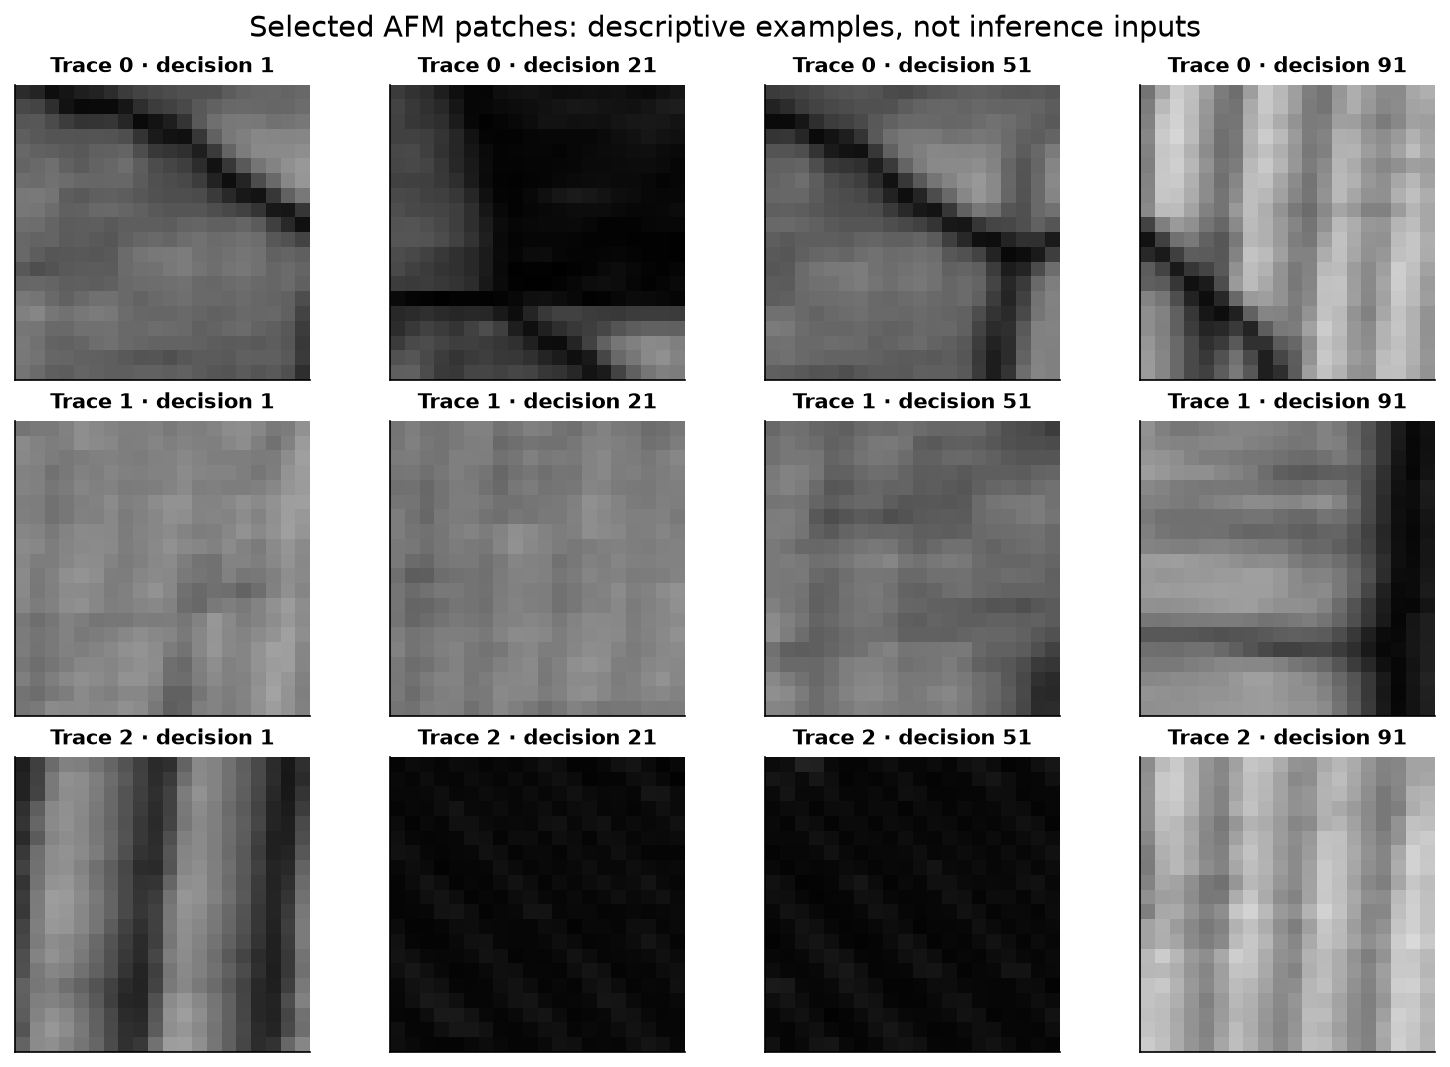

In [ ]:
fig, axes = plt.subplots(3,4,figsize=(10,7),layout='constrained')
steps = [0,20,50,90]
for i in range(3):
    for col,t in enumerate(steps):
        ax = axes[i,col]
        ax.imshow(images[i,t,y[i,t]],cmap='gray',vmin=0,vmax=1)
        ax.set_title(f'Trace {i} · decision {t+1}',fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Selected AFM patches: descriptive examples, not inference inputs',fontsize=14)
plt.show()

**Interpretation.** The selected patches vary in contrast, boundary structure, smoothness, and directional texture. A common intensity scale is used across panels. These outcome-selected examples illustrate the traces; they do not establish a reward by themselves and are never passed to the predictor as a current chosen image.

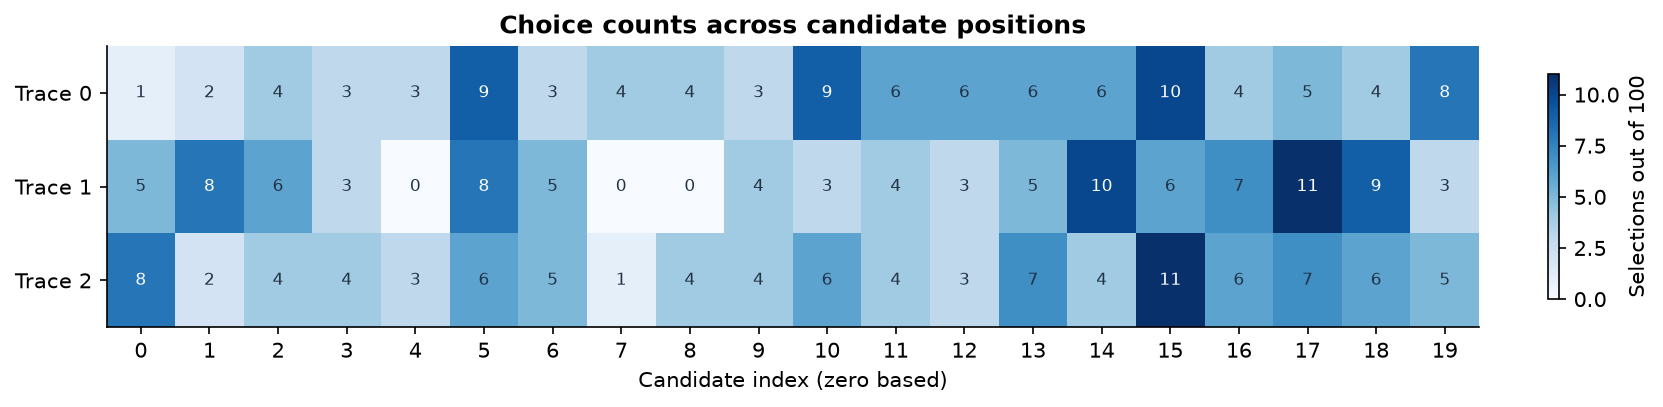

In [ ]:
counts = np.array([np.bincount(choices,minlength=20) for choices in y])
fig, ax = plt.subplots(figsize=(11,2.6),layout='constrained')
im = ax.imshow(counts,cmap='Blues',aspect='auto',vmin=0)
for i in range(3):
    for j in range(20):
        ax.text(j,i,str(counts[i,j]),ha='center',va='center',fontsize=8,
                color='white' if counts[i,j] > counts.max()*.65 else '#243447')
ax.set(xticks=range(20),yticks=range(3),yticklabels=[f'Trace {i}' for i in range(3)],
       xlabel='Candidate index (zero based)',title='Choice counts across candidate positions')
fig.colorbar(im,ax=ax,label='Selections out of 100',shrink=.8)
plt.show()

**Interpretation.** Choices are not concentrated at a single candidate position. More decisively, traces 0 and 1 receive **the same ordered sets at all 100 times yet agree on only one choice**. Their choices therefore reveal different policies on matched visual offers. All 2,000 candidate instances in each of these traces occur in the other; trace 2 shares 70/2,000 instances. These are three behavioral traces but only two distinct offered-set sequences from one scan, limiting independence. The model uses neither candidate index, scan position, nor trace ID as a feature.

## 3. Methods: interpretable visual utility

### 3.1 Stateless visual reward

The retained patch-only rule is the fraction of mean-centered Fourier power at radial frequencies at least $0.25$ cycles/pixel. It favors high-frequency structure and was identified during previous exploration. It is a **fixed ranking rule**, not a recovered universal GPT objective. Cross-trace temperature calibration changes probabilities, not ranking.

### 3.2 Visual descriptors

We reuse the exact working descriptors: 14 intensity/texture summaries plus 16 morphology summaries, for **30 features**. They cover brightness and contrast; gradients, edges and orientation; entropy and spectral texture; roughness and curvature; smoothing at two scales; neighbor correlation; and connected dark components. The full extraction code is inline below. Descriptor names are used in the later preference figure.

In [ ]:
FEATURE_NAMES = [
    'mean_intensity', 'intensity_std', 'p10', 'p90', 'intensity_iqr',
    'mean_gradient', 'gradient_std', 'edge_density', 'gradient_anisotropy',
    'mean_abs_laplacian', 'hist_entropy', 'highfreq_power_fraction',
    'normalized_roughness', 'quadrant_heterogeneity',
]

EPS = 1e-9

def patch_features(patch):
    """Image-patch summary; never relies on selected label."""
    p = np.asarray(patch, dtype=np.float64).squeeze()
    if p.ndim == 3:
        p = p.mean(axis=-1)
    if p.ndim != 2:
        raise ValueError(f'Expected 2D patch, got {p.shape}')
    p = np.nan_to_num(p, nan=0.0, posinf=0.0, neginf=0.0)
    h, w = p.shape
    mu, sd = float(np.mean(p)), float(np.std(p))
    q10, q25, q75, q90 = np.percentile(p, [10, 25, 75, 90])
    gy, gx = np.gradient(p)
    agx, agy = np.abs(gx), np.abs(gy)
    gradient = np.hypot(gx, gy)
    grad_mean = float(np.mean(gradient))
    grad_std = float(np.std(gradient))
    edge_fraction = float(np.mean(gradient > (0.7 * sd + EPS)))
    anisotropy = abs(float(agx.mean() - agy.mean())) / (float(agx.mean() + agy.mean()) + EPS)
    lap = np.gradient(gx, axis=1) + np.gradient(gy, axis=0)
    abs_lap = float(np.mean(np.abs(lap)))

    if float(np.ptp(p)) < EPS:
        entropy = 0.0
    else:
        counts = np.histogram(p, bins=16, range=(float(p.min()), float(p.max()) + EPS))[0]
        prob = counts.astype(float) / max(int(counts.sum()), 1)
        entropy = float(-np.sum(prob[prob > 0] * np.log(prob[prob > 0])) / np.log(16.0))

    power = np.abs(np.fft.rfft2(p - mu)) ** 2
    fy = np.abs(np.fft.fftfreq(h))[:, None]
    fx = np.fft.rfftfreq(w)[None, :]
    highmask = (fx ** 2 + fy ** 2) >= 0.25 ** 2
    hf = float(np.sum(power * highmask) / (np.sum(power) + EPS))

    blocks = [p[:h // 2, :w // 2], p[:h // 2, w // 2:],
              p[h // 2:, :w // 2], p[h // 2:, w // 2:]]
    heterogeneity = float(np.mean([abs(float(b.mean()) - mu) for b in blocks])) / (sd + EPS)
    return np.array([
        mu, sd, q10, q90, q75 - q25,
        grad_mean, grad_std, edge_fraction, anisotropy,
        abs_lap, entropy, hf,
        grad_mean / (sd + EPS), heterogeneity,
    ], dtype=float)

In [ ]:
MORPH_NAMES = ['intensity_skew', 'intensity_kurtosis', 'gradient_concentration',
         'gradient_cv', 'structure_coherence', 'signed_gradient_orientation',
         'blur1_sd_fraction', 'blur2_sd_fraction', 'mean_neighbor_correlation',
         'neighbor_correlation_anisotropy', 'spectral_peak_fraction',
         'spectral_centroid', 'dark_component_fraction', 'dark_component_count',
         'normalized_laplacian', 'normalized_intensity_range']

def morphology_features(p):
    p=np.asarray(p,dtype=float);mu=p.mean();sd=p.std()+EPS;q=(p-mu)/sd
    gy,gx=np.gradient(p);g=np.hypot(gx,gy);gm=g.mean()+EPS
    xx=(gx*gx).mean(); yy=(gy*gy).mean();xy=(gx*gy).mean()
    coherence=np.sqrt((xx-yy)**2+4*xy*xy)/(xx+yy+EPS)
    orientation=(xx-yy)/(xx+yy+EPS)
    corrx=(q[:,:-1]*q[:,1:]).mean();corry=(q[:-1]*q[1:]).mean()
    power=np.abs(np.fft.rfft2(p-mu))**2
    fy=np.fft.fftfreq(p.shape[0])[:,None];fx=np.fft.rfftfreq(p.shape[1])[None,:]
    radial=np.sqrt(fy*fy+fx*fx)
    labs,n=label(p<np.percentile(p,25))
    sizes=np.bincount(labs.ravel())[1:]
    large=sizes[sizes>=4]
    lap=np.gradient(gx,axis=1)+np.gradient(gy,axis=0)
    return np.array([(q**3).mean(),(q**4).mean(),np.percentile(g,95)/gm,
        g.std()/gm,coherence,orientation,
        gaussian_filter(p,1).std()/sd,gaussian_filter(p,2).std()/sd,
        (corrx+corry)/2,abs(corrx-corry),power.max()/(power.sum()+EPS),
        (power*radial).sum()/(power.sum()+EPS),
        (large.max() if len(large) else 0)/p.size,len(large)/p.size,
        np.mean(np.abs(lap))/sd,np.ptp(p)/sd])

In [ ]:
FEATURES = FEATURE_NAMES + MORPH_NAMES
_feature_cache = {}

def describe_patch(patch):
    """Pure image descriptors; cache values contain neither labels nor choices."""
    p = np.asarray(patch)
    if p.shape != (20,20) or not np.isfinite(p).all():
        raise ValueError('Each candidate must be a finite 20-by-20 image.')
    key = image_key(p)
    if key not in _feature_cache:
        _feature_cache[key] = np.concatenate([patch_features(p),morphology_features(p)])
    return _feature_cache[key].copy()

def normalize(raw):
    """Standardize across only the 20 candidates in each current offered set."""
    return np.clip((raw-raw.mean(axis=1,keepdims=True)) /
                   (raw.std(axis=1,keepdims=True)+EPS),-4,4)

def representation(z, quadratic=False):
    if not quadratic:
        return z
    square = z*z
    square = (square-square.mean(axis=1,keepdims=True)) / (square.std(axis=1,keepdims=True)+EPS)
    return np.concatenate([z,square],axis=-1)

raw = np.array([[[describe_patch(p) for p in offered] for offered in trace] for trace in images])
z = np.stack([normalize(trace) for trace in raw])
assert raw.shape == (3,100,20,30) and np.isfinite(z).all()
pd.DataFrame({'representation':['linear','quadratic extension'],
              'dimension':[30,60],
              'construction':['current-set standardized descriptors (clipped ±4)',
                              'linear descriptors plus current-set standardized squared descriptors']})

,representation,dimension,construction
0,linear,30,current-set standardized descriptors (clipped ±4)
1,quadratic extension,60,linear descriptors plus current-set standardized squared descriptors


### 3.3 The retained online estimator

Let $f(p)$ be the raw descriptors and $z_{tj}$ their standardized, clipped values within the **current** 20 candidates. The retained linear representation is $\phi_{tj}=z_{tj}$. One validation fold instead uses

$$\phi_{tj}=\left[z_{tj},\;\operatorname{standardize}_{j}(z_{tj}^{\,2})\right],$$

with 60 coefficients and no interaction terms. Thus the quadratic variant is not a 30-coefficient linear reward on raw features.

The general decomposition is

$$U_t(p_{tj})=w_{\rm global}^{\mathsf T}\phi_{tj}+w_t^{\mathsf T}\phi_{tj}.$$

**In the retained model $w_{\rm global}=0$.** Its Gaussian prior is centered at zero; learned global priors were tested but not retained. Given only $H_t$, we estimate a trace-specific preference vector:

$$\widehat w_t=\arg\min_w\left\{\sum_{s<t}\left[
\log\sum_{j=0}^{19}\exp(w^{\mathsf T}\phi_{sj})-w^{\mathsf T}\phi_{s,y_s}
\right]+\frac{10}{2}\lVert w\rVert_2^2\right\}.$$

$$P(y_t=j\mid C_t,H_t)=\frac{\exp(\beta\widehat w_t^{\mathsf T}\phi_{tj})}
{\sum_k\exp(\beta\widehat w_t^{\mathsf T}\phi_{tk})}.$$

Both selected and rejected alternatives contribute to the conditional likelihood. The penalty shrinks short histories; the optimizer warm-starts from the last fit but solves the full past-data objective. At $t=0$, $w=0$ and probabilities are uniform. **Every prediction precedes the current observation.** All prior paired examples have equal weight: there is no explicit recency term or hidden recurrent state. Inverse temperature $\beta$ is fitted on other traces only for nested evaluation.

In [ ]:
def evaluate(scores,labels):
    row=np.arange(len(labels))
    return {'top1':float(np.mean(scores.argmax(axis=-1)==labels)),
            'top3':float(np.mean(np.any(np.argsort(scores,axis=-1)[:,-3:]==labels[:,None],axis=-1))),
            'nll':float(np.mean(logsumexp(scores,axis=-1)-scores[row,labels])),
            'steps':len(labels)}

def fit(x,y,strength=10,start=None):
    d=x.shape[-1]
    if not len(y):return np.zeros(d)
    row=np.arange(len(y))
    def objective(w):
        a=x@w;n=logsumexp(a,axis=1);p=np.exp(a-n[:,None])
        value=(n-a[row,y]).sum()+strength*np.dot(w,w)/2
        grad=np.einsum('tk,tkf->f',p,x)-x[row,y].sum(axis=0)+strength*w
        return value,grad
    r=minimize(objective,np.zeros(d) if start is None else start,jac=True,method='L-BFGS-B',
               options={'maxiter':100,'ftol':1e-9})
    if not r.success:raise RuntimeError(r.message)
    return r.x

def prequential(x,observed_labels=None,strength=10):
    """Predict THEN reveal the current label, or explicitly feed own prediction.

    x contains only deterministic per-current-set visual features. Passing
    observed_labels=None means zero observed choices, entirely self feedback.
    """
    history=[];w=np.zeros(x.shape[-1]);scores=[];weights=[]
    for t in range(len(x)):
        if t:w=fit(x[:t],np.asarray(history,dtype=int),strength,w)
        score=x[t]@w;scores.append(score);weights.append(w.copy())
        update=int(score.argmax()) if observed_labels is None else int(observed_labels[t])
        history.append(update)
    return np.asarray(scores),np.asarray(weights),np.asarray(history)

def inverse_temperature(scores,y):
    def loss(b):return np.mean(logsumexp(b*scores,axis=1)-b*scores[np.arange(len(y)),y])
    return float(minimize_scalar(loss,bounds=(0,8),method='bounded').x)

### 3.4 Alternatives and the decision to retain the benchmark

Earlier experiments tested nearest/average selected-patch similarity, Euclidean/Manhattan/cosine distances, feature subsets, conditional logit, recency windows, weighted memory, selected-versus-rejected updating, and global-plus-local priors. The original five-feature nearest-selected-patch rule reached 16.7% top-1; a pooled history-aware conditional logit reached 7.3%. These motivated direct estimation of each trace's relative visual utility.

The fixed 30-feature linear recipe reaches 37.0%, but it was identified during exploration. The retained **nested selection procedure** reaches 36.3%. A later expanded challenger reaches 36.7%, with lower top-3 (61.3%) and worse log loss (2.134); one extra correct choice does not establish improvement. We preserve the benchmark rather than choose the largest explored number.

## 4. Experimental design and leakage boundaries

**Outer evaluation:** hold out one GPT trace, choose the model using only the other two traces, then predict the held trace chronologically. **Inner validation:** swap training/validation roles between those two traces; average top-1 selects the recipe, with log loss as tie-breaker. Calibration is fitted on training traces, then applied to the held trace. Learning from earlier choices of the held target is permitted only in the observed-history regime; this is online adaptation, not a future-label leak.

The original library and subsequent research were designed after inspecting these same traces. Nested selection limits parameter-selection leakage **within the frozen experiment**, but cannot remove bias from that adaptive library design. There is no untouched final test. Here we replay the **frozen originally selected recipes**, rebuilding image features and refitting training-only calibration. We do not repeat the search or select a new model. The embedded table records its leading inner-validation candidates.

Top-1 is `argmax` accuracy; top-3 is the fraction whose label is among the three highest scores; log loss is mean negative log probability in nats. At uniform cold-start ties, index 0 is the deterministic top-1; historical result tables use NumPy's `argsort` top-3 tie convention. Uniform **random** expectation is 5%/15%, irrespective of these realized deterministic ties.

Negative controls remove true history, scramble only already-observed labels, transfer another trace's history, or use index-only preferences. These answer different questions and are labeled by their evaluation population. Self-fed replay receives its own predicted labels rather than GPT's choices. Its candidate sets remain those in the logs, so it does not measure an action-dependent microscope trajectory.

In [ ]:
INNER_SELECTION = [{'outer_held': 0,
  'training_traces': [1, 2],
  'inner_rank': 1,
  'recipe': 'online_extended30_ridge10',
  'inner_top1': 0.4,
  'inner_log_loss': 2.023408761372532},
 {'outer_held': 0,
  'training_traces': [1, 2],
  'inner_rank': 2,
  'recipe': 'global2_similarity_online_reward_alpha0.02',
  'inner_top1': 0.4,
  'inner_log_loss': 2.2251226330108165},
 {'outer_held': 1,
  'training_traces': [0, 2],
  'inner_rank': 1,
  'recipe': 'online_extended30_quadratic_ridge10',
  'inner_top1': 0.42000000000000004,
  'inner_log_loss': 1.9635845147853093},
 {'outer_held': 1,
  'training_traces': [0, 2],
  'inner_rank': 2,
  'recipe': 'online_extended30_ridge10',
  'inner_top1': 0.41500000000000004,
  'inner_log_loss': 1.9557108829500052},
 {'outer_held': 2,
  'training_traces': [0, 1],
  'inner_rank': 1,
  'recipe': 'online_extended30_ridge10',
  'inner_top1': 0.29500000000000004,
  'inner_log_loss': 2.3585217645954084},
 {'outer_held': 2,
  'training_traces': [0, 1],
  'inner_rank': 2,
  'recipe': 'online_extended30_quadratic_ridge10',
  'inner_top1': 0.29500000000000004,
  'inner_log_loss': 2.373758713045459}]

FROZEN_RECIPES = ["linear", "quadratic", "linear"]
# These are validation-fold provenance, never a trace-ID deployment rule.
pd.DataFrame(INNER_SELECTION).round(3)

,outer_held,training_traces,inner_rank,recipe,inner_top1,inner_log_loss
0,0,"[1, 2]",1,online_extended30_ridge10,0.400,2.023
1,0,"[1, 2]",2,global2_similarity_online_reward_alpha0.02,0.400,2.225
2,1,"[0, 2]",1,online_extended30_quadratic_ridge10,0.420,1.964
3,1,"[0, 2]",2,online_extended30_ridge10,0.415,1.956
4,2,"[0, 1]",1,online_extended30_ridge10,0.295,2.359
5,2,"[0, 1]",2,online_extended30_quadratic_ridge10,0.295,2.374


In [ ]:
# Rebuild the retained predictions and the comparison models from raw images.
linear, quadratic, self_fed, weights, quadratic_weights = [],[],[],[],[]
for i in range(3):
    s,w,_ = prequential(z[i],y[i]); linear.append(s); weights.append(w)
    s,w,_ = prequential(representation(z[i],True),y[i]); quadratic.append(s); quadratic_weights.append(w)
    s,_,updates = prequential(z[i],None); self_fed.append(s)
    np.testing.assert_array_equal(updates,s.argmax(axis=1))
linear,quadratic,self_fed = map(np.asarray,[linear,quadratic,self_fed])
weights,quadratic_weights = map(np.asarray,[weights,quadratic_weights])
retained = np.zeros_like(linear)
stateless = np.zeros_like(linear)
global_visual = np.zeros_like(linear)
hf = raw[...,11]
hf = np.clip((hf-hf.mean(axis=-1,keepdims=True))/(hf.std(axis=-1,keepdims=True)+EPS),-4,4)
calibration_rows = []
for held,recipe in enumerate(FROZEN_RECIPES):
    train = [i for i in range(3) if i != held]
    base = quadratic if recipe == 'quadratic' else linear
    beta = inverse_temperature(np.concatenate(base[train]),np.concatenate(y[train]))
    hf_beta = inverse_temperature(np.concatenate(hf[train]),np.concatenate(y[train]))
    retained[held] = beta*base[held]
    stateless[held] = hf_beta*hf[held]
    g = fit(np.concatenate(z[train]),np.concatenate(y[train]))
    global_visual[held] = z[held] @ g
    calibration_rows.append({'held trace':held,'recipe':recipe,'ridge':10,
                             'training traces':str(train),'online beta':beta,'stateless beta':hf_beta})

main_scores = {'Random':np.zeros_like(retained),'Stateless':stateless,
               'Observed history':retained,'Cold self-fed':self_fed}
rows = []
for name,scores in main_scores.items():
    m = evaluate(scores.reshape(-1,20),y.ravel())
    if name == 'Random':
        m.update(top1=.05,top3=.15)
    rows.append({'model':name,**m})
results = pd.DataFrame(rows).set_index('model')
expected = np.array([[.05,.15,np.log(20)],[.14,86/300,3.03378445],
                     [109/300,188/300,2.11880835],[16/300,47/300,6.790734]])
np.testing.assert_allclose(results[['top1','top3','nll']],expected,atol=2e-6)
assert np.array_equal((retained.argmax(axis=-1) == y).sum(axis=1),[31,26,52])
pd.DataFrame(calibration_rows).round(4)

,held trace,recipe,ridge,training traces,online beta,stateless beta
0,0,linear,10,"[1, 2]",0.9100,0.5802
1,1,quadratic,10,"[0, 2]",0.8640,0.3793
2,2,linear,10,"[0, 1]",0.9756,0.1201


## 5. Results

### 5.1 Main comparison

The table and figure below are freshly recomputed from the three raw GPT traces. The observed-history row uses the retained nested recipes, while cold self-fed uses the fixed linear runtime from a uniform initial state. Their information regimes differ, so 36.3% must not be described as autonomous accuracy.

In [ ]:
def result_table(frame):
    out = frame[['top1','top3','nll']].copy()
    out.columns = ['Top-1','Top-3','Log loss (nats)']
    out['Top-1'] = out['Top-1'].map(lambda v:f'{100*v:.1f}%')
    out['Top-3'] = out['Top-3'].map(lambda v:f'{100*v:.1f}%')
    out['Log loss (nats)'] = out['Log loss (nats)'].map(lambda v:f'{v:.3f}')
    return out
result_table(results)

,Top-1,Top-3,Log loss (nats)
model,,,
Random,5.0%,15.0%,2.996
Stateless,14.0%,28.7%,3.034
Observed history,36.3%,62.7%,2.119
Cold self-fed,5.3%,15.7%,6.791


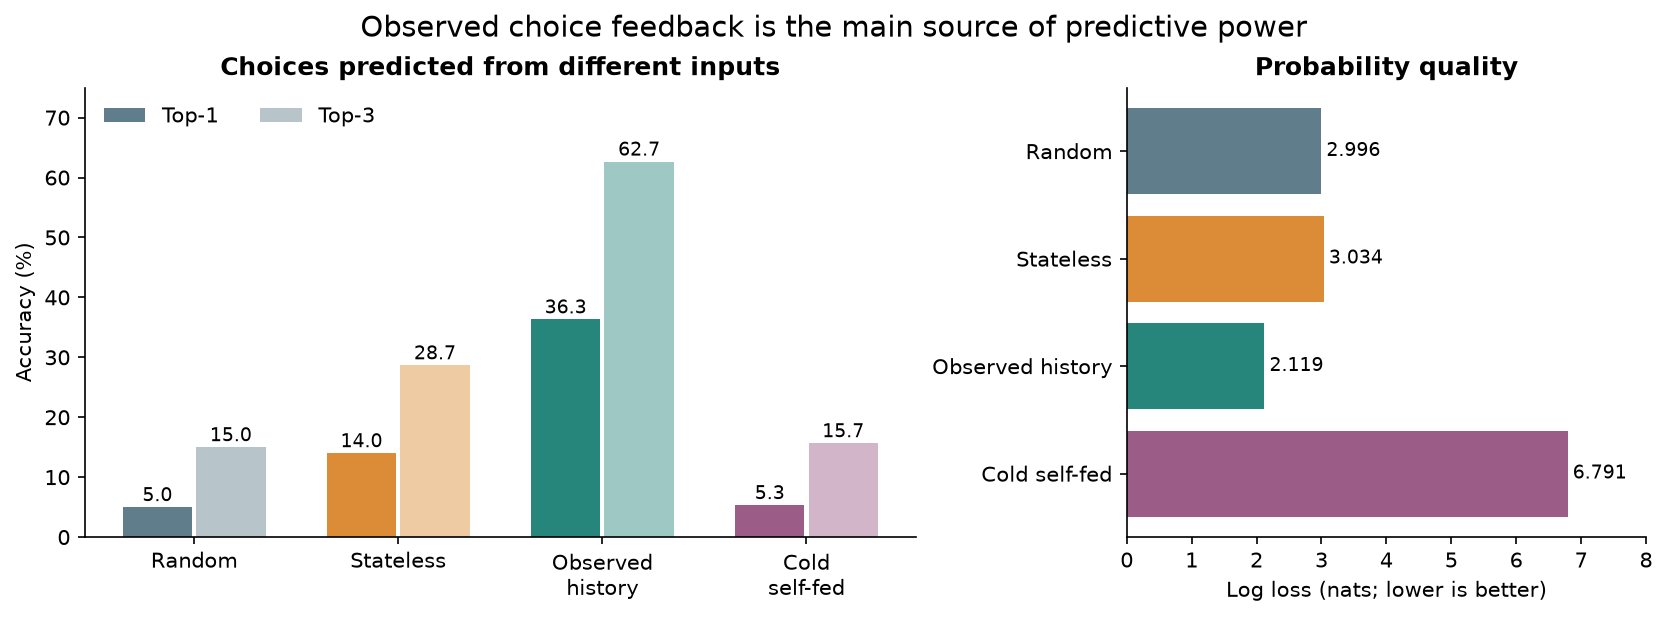

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(11,4),layout='constrained',gridspec_kw={'width_ratios':[1.6,1]})
xx = np.arange(4)
a,b = axes
for offset,column,alpha in [(-.18,'top1',1),(.18,'top3',.45)]:
    bars = a.bar(xx+offset,100*results[column],width=.34,color=COLORS,alpha=alpha,
                 label='Top-1' if column=='top1' else 'Top-3')
    for rect,v in zip(bars,results[column]):
        a.text(rect.get_x()+rect.get_width()/2,100*v+1,f'{100*v:.1f}',ha='center',fontsize=9)
a.set(xticks=xx,xticklabels=['Random','Stateless','Observed\nhistory','Cold\nself-fed'],
      ylabel='Accuracy (%)',ylim=(0,75),title='Choices predicted from different inputs')
a.legend(frameon=False,ncols=2,loc='upper left')
bars = b.barh(xx,results.nll,color=COLORS)
b.set(yticks=xx,yticklabels=['Random','Stateless','Observed history','Cold self-fed'],
      xlabel='Log loss (nats; lower is better)',xlim=(0,8),title='Probability quality')
b.invert_yaxis()
for rect,v in zip(bars,results.nll): b.text(v+.08,rect.get_y()+rect.get_height()/2,f'{v:.3f}',va='center',fontsize=9)
fig.suptitle('Observed choice feedback is the main source of predictive power',fontsize=14)
plt.show()

**Interpretation.** Observed-history top-1 improves by **31.3 percentage points over random** and **19.7 points over the original 16.7% similarity model**. The patch-only rule has useful ranking signal but slightly worse log loss than uniform, indicating poorly transferring probabilities. Cold self-feeding almost eliminates the accuracy gain and becomes highly overconfident. These results share previously explored data; none is an independent final-test estimate.

In [ ]:
per_trace = pd.DataFrame([{'trace':i,**evaluate(retained[i],y[i])} for i in range(3)]).set_index('trace')
result_table(per_trace)

,Top-1,Top-3,Log loss (nats)
trace,,,
0,31.0%,59.0%,2.254
1,26.0%,53.0%,2.467
2,52.0%,76.0%,1.636


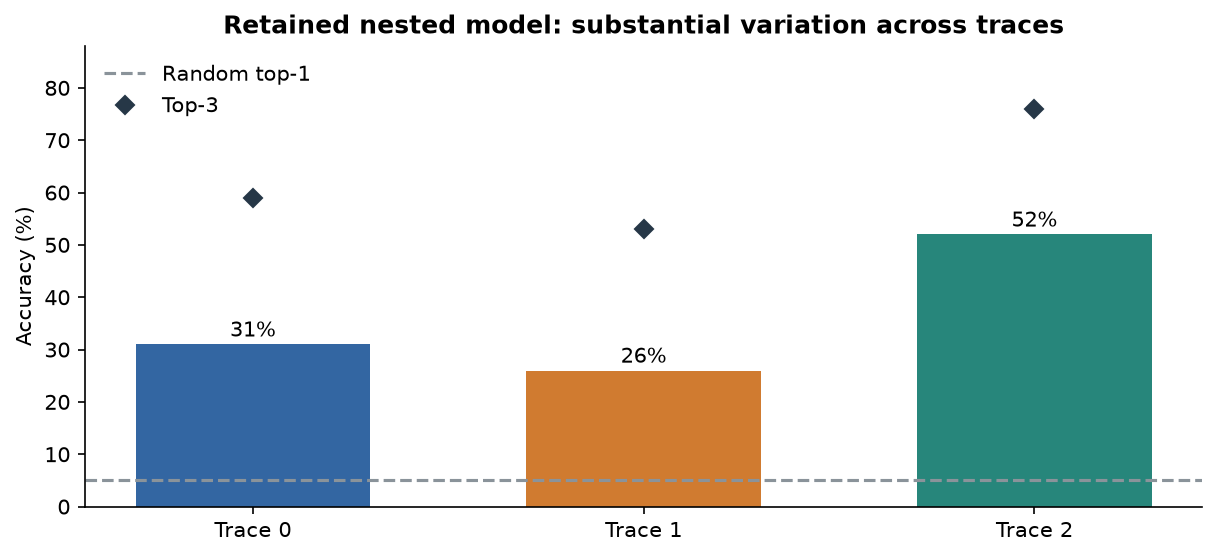

In [ ]:
fig,ax = plt.subplots(figsize=(8,3.6),layout='constrained')
for i in range(3):
    ax.bar(i,100*per_trace.loc[i,'top1'],color=TRACE_COLORS[i],width=.6)
    ax.text(i,100*per_trace.loc[i,'top1']+1.5,f"{100*per_trace.loc[i,'top1']:.0f}%",ha='center')
    ax.plot(i,100*per_trace.loc[i,'top3'],'D',color='#263747',ms=6)
ax.axhline(5,color='#8A939A',ls='--',label='Random top-1')
ax.plot([],[],'D',color='#263747',label='Top-3')
ax.set(xticks=range(3),xticklabels=['Trace 0','Trace 1','Trace 2'],ylim=(0,88),
       ylabel='Accuracy (%)',title='Retained nested model: substantial variation across traces')
ax.legend(frameon=False,loc='upper left')
plt.show()

**Interpretation and uncertainty.** Top-1 is 31%, 26%, and 52%, showing substantial trace heterogeneity. There are only three traces and two distinct offer sequences, not 300 independent experimental units. A prior paired trace/time-block bootstrap (10-decision blocks) gave a descriptive 95% interval of **+8.7 to +32.3 points** for improvement over the original similarity rule, but a three-trace $t$ interval was **−4.8 to +44.2 points**. The latter includes zero; neither corrects adaptive study design. We do not attach an IID binomial significance claim to these accuracies. The next table retains the prior paired comparison rather than rerunning uncertainty on a newly selected model.

In [ ]:
pd.DataFrame([
    {'comparison':'Retained minus original similarity','gain (pp)':19.7,
     'uncertainty':'trace/time-block bootstrap: +8.7 to +32.3 pp'},
    {'comparison':'Same gain, only three trace units','gain (pp)':19.7,
     'uncertainty':'trace-level t interval: −4.8 to +44.2 pp'},
    {'comparison':'Expanded challenger minus retained','gain (pp)':0.3,
     'uncertainty':'paired block-bootstrap interval: −1.7 to +2.0 pp'}
])

,comparison,gain (pp),uncertainty
0,Retained minus original similarity,19.7,trace/time-block bootstrap: +8.7 to +32.3 pp
1,"Same gain, only three trace units",19.7,trace-level t interval: −4.8 to +44.2 pp
2,Expanded challenger minus retained,0.3,paired block-bootstrap interval: −1.7 to +2.0 pp


### 5.2 How many observations are needed?

To separate adaptation from changing test difficulty, fit the fixed linear recipe on the first $K\in\{0,1,5,10,20,50\}$ observed choices, **freeze its weights**, and score the same final 50 decisions (zero-based 50–99) for every $K$. No labels in that common evaluation window update the frozen model. This diagnostic is a fixed explored recipe, not a newly selected nested model.

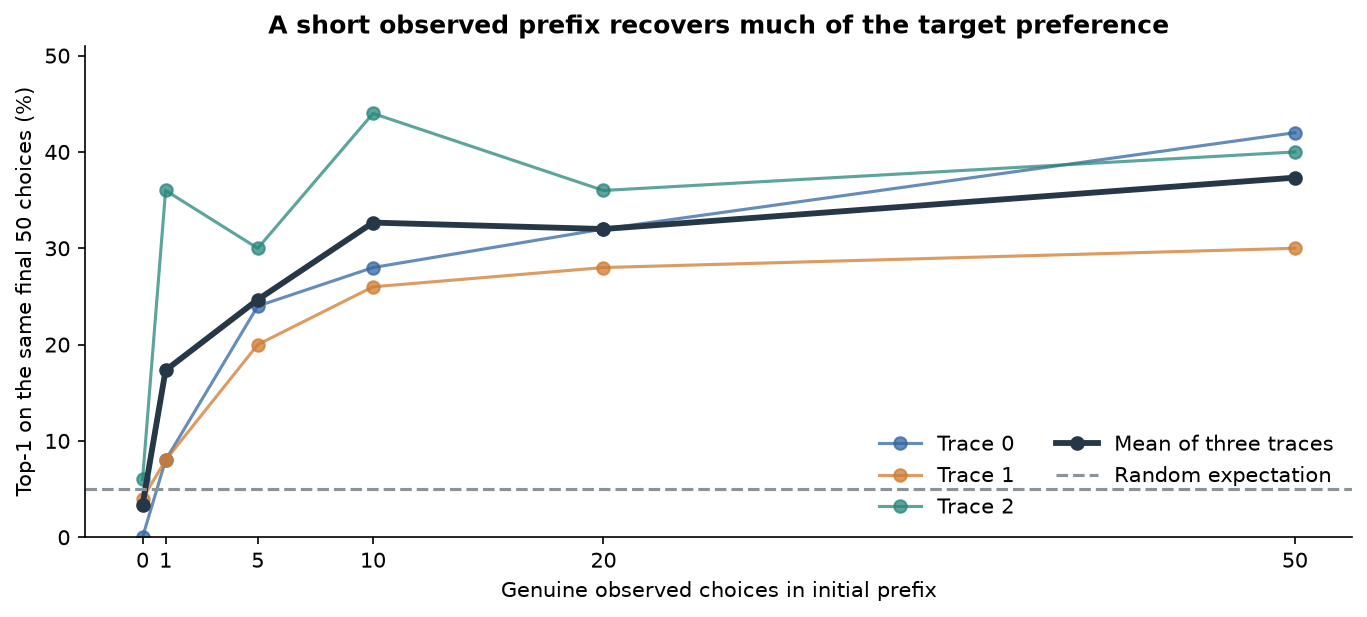

In [ ]:
PREFIXES = [0,1,5,10,20,50]
prefix_rows = []
for i in range(3):
    for k in PREFIXES:
        w = fit(z[i,:k],y[i,:k])
        prefix_rows.append({'trace':i,'observed prefix':k,**evaluate(z[i,50:]@w,y[i,50:])})
prefix_curve = pd.DataFrame(prefix_rows)
prefix_means = prefix_curve.groupby('observed prefix').top1.mean()
np.testing.assert_allclose(prefix_means.loc[[10,50]],[.32666666666666666,.37333333333333335])
fig,ax = plt.subplots(figsize=(9,4),layout='constrained')
for i in range(3):
    q = prefix_curve[prefix_curve.trace==i]
    ax.plot(q['observed prefix'],100*q.top1,'o-',color=TRACE_COLORS[i],alpha=.75,label=f'Trace {i}')
ax.plot(PREFIXES,100*prefix_means,'o-',lw=2.8,color='#263747',label='Mean of three traces')
ax.axhline(5,color='#8A939A',ls='--',label='Random expectation')
ax.set(xticks=PREFIXES,ylim=(0,51),xlabel='Genuine observed choices in initial prefix',
       ylabel='Top-1 on the same final 50 choices (%)',title='A short observed prefix recovers much of the target preference')
ax.legend(frameon=False,ncols=2,loc='lower right')
plt.show()

**Interpretation.** Ten observed choices give **32.7%** and fifty give **37.3%** on a common future window. Gains are not monotone within every trace: finite samples, shrinkage, and ambiguous visual cues matter. At $K=0$ the realized deterministic tie rule gives 3.3%, while uniform random expectation remains 5%. The curve supports rapid identification of a persistent trace policy; it does not show that GPT itself learned from its earlier decisions.

In [ ]:
# A complementary descriptive curve uses genuine continuously observed history.
bins = [('0',0,1),('1–5',1,6),('6–10',6,11),('11–20',11,21),('21–50',21,51),('>50',51,100)]
observed_bins = []
for name,lo,hi in bins:
    row = {'previous choices':name,'decisions per trace':hi-lo}
    for i in range(3):
        row[f'Trace {i}'] = f'{100*evaluate(linear[i,lo:hi],y[i,lo:hi])["top1"]:.1f}%'
    observed_bins.append(row)
pd.DataFrame(observed_bins)

,previous choices,decisions per trace,Trace 0,Trace 1,Trace 2
0,0,1,0.0%,0.0%,0.0%
1,1–5,5,0.0%,20.0%,40.0%
2,6–10,5,20.0%,20.0%,40.0%
3,11–20,10,30.0%,10.0%,90.0%
4,21–50,30,20.0%,36.7%,66.7%
5,>50,49,42.9%,28.6%,38.8%


The continuously updated time bins above contain different candidate sets, and the first bins are tiny. They are descriptive, not a substitute for the fixed-window learning curve.

### 5.3 History controls: matched offers and randomized observations

For the matched comparison, apply trace 1's past-only linear preference weights to trace 0's current offers, and vice versa. All current offers are identical, so this changes the behavioral history while holding images fixed. The randomized control instead permutes **only the already-observed label indices** among their past choice contexts at each time; it never reads a future choice. Its ten original repetitions are embedded below to preserve the validated experiment without unnecessarily rerunning 3,000 fits.

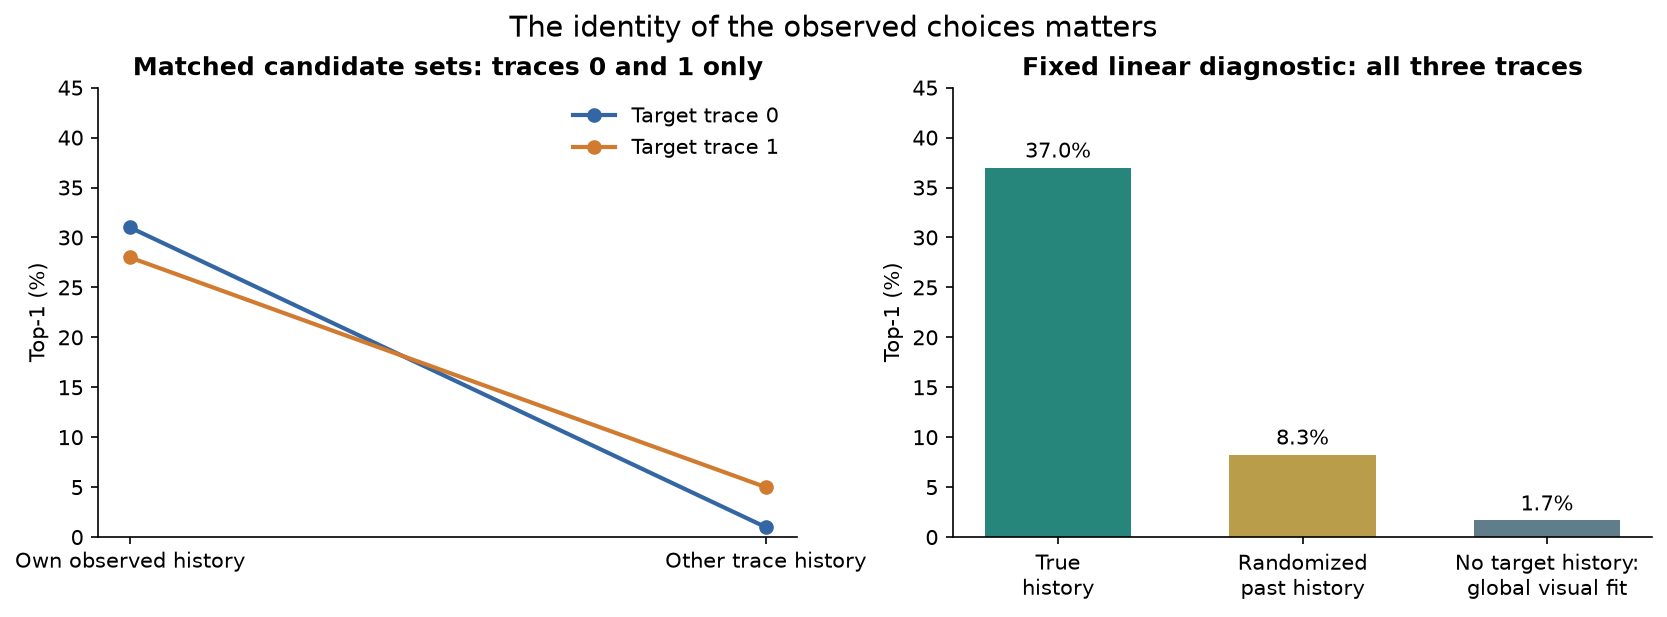

In [ ]:
ARCHIVED_RANDOMIZED_TOP1 = np.array([[0.04, 0.07, 0.17], [0.08, 0.06, 0.16], [0.04, 0.03, 0.07], [0.08, 0.11, 0.1], [0.04, 0.05, 0.16], [0.07, 0.07, 0.12], [0.05, 0.09, 0.08], [0.04, 0.09, 0.08], [0.08, 0.05, 0.09], [0.08, 0.1, 0.13]])

# Row = repetition, column = trace. This is archived validated data, not a fresh fit.
randomized_mean = float(ARCHIVED_RANDOMIZED_TOP1.mean())
assert np.isclose(randomized_mean,.08266666666666667)
swapped = np.stack([np.einsum('tjd,td->tj',z[0],weights[1]),
                    np.einsum('tjd,td->tj',z[1],weights[0])])
own_pair = [evaluate(linear[i],y[i])['top1'] for i in [0,1]]
swap_pair = [evaluate(swapped[i],y[i])['top1'] for i in [0,1]]
np.testing.assert_allclose(own_pair,[.31,.28])
np.testing.assert_allclose(swap_pair,[.01,.05])
full_linear_acc = evaluate(linear.reshape(-1,20),y.ravel())['top1']
global_acc = evaluate(global_visual.reshape(-1,20),y.ravel())['top1']
fig,axes = plt.subplots(1,2,figsize=(11,4),layout='constrained')
a,b = axes
for i in [0,1]:
    a.plot([0,1],100*np.array([own_pair[i],swap_pair[i]]),'o-',color=TRACE_COLORS[i],lw=2,label=f'Target trace {i}')
a.set(xticks=[0,1],xticklabels=['Own observed history','Other trace history'],ylim=(0,45),
      ylabel='Top-1 (%)',title='Matched candidate sets: traces 0 and 1 only')
a.legend(frameon=False)
vals = [full_linear_acc,randomized_mean,global_acc]
bars = b.bar(range(3),100*np.array(vals),color=['#27867B','#BA9D4A','#607D8B'],width=.6)
for rect,v in zip(bars,vals): b.text(rect.get_x()+rect.get_width()/2,100*v+1,f'{100*v:.1f}%',ha='center')
b.set(xticks=range(3),xticklabels=['True\nhistory','Randomized\npast history','No target history:\nglobal visual fit'],
      ylim=(0,45),ylabel='Top-1 (%)',title='Fixed linear diagnostic: all three traces')
fig.suptitle('The identity of the observed choices matters',fontsize=14)
plt.show()

**Interpretation.** On identical offers, own versus swapped history gives **31% versus 1%** for trace 0 and **28% versus 5%** for trace 1. Across all traces, fixed-linear true history gives 37.0%, randomized past history 8.3%, and global visual preferences without target observations 1.7%. The 37.0% diagnostic here is intentionally distinguished from the 36.3% nested benchmark. Randomization retains the marginal past index distribution, so its degradation implicates the association between choices and visual contexts rather than index counts alone. A separate index-only model gives 5.7%.

In [ ]:
def reproduce_randomized_control(z,y,repetitions=10,seed=61016):
    """Optional exact prior causal control; only y[i,:t] can be permuted."""
    rng = np.random.default_rng(seed)
    rows = []
    for rep in range(repetitions):
        for i in range(len(y)):
            scores = np.zeros((len(y[i]),20)); w = np.zeros(z.shape[-1])
            for t in range(1,len(y[i])):
                past_y = y[i,rng.permutation(t)]
                w = fit(z[i,:t],past_y,start=w)
                scores[t] = z[i,t]@w
            rows.append({'repetition':rep,'trace':i,**evaluate(scores,y[i])})
    return pd.DataFrame(rows)

REPRODUCE_RANDOMIZED_CONTROL = False  # Already validated; set True to replay all ten repetitions.
if REPRODUCE_RANDOMIZED_CONTROL:
    reproduced_null = reproduce_randomized_control(z,y)
    np.testing.assert_allclose(reproduced_null.top1.to_numpy().reshape(10,3),ARCHIVED_RANDOMIZED_TOP1)

# Earlier validated fixed-recipe memory ablations, retained as archived observations.
memory = pd.DataFrame({'History':['Recent 5','Recent 10','Recent 20','Recent 50','Complete','Half-life 10','Half-life 30'],
                       'Top-1':['26.3%','33.7%','34.7%','35.7%','37.0%','37.0%','37.7%'],
                       'Status':['archived fixed linear diagnostic']*7})
memory

,History,Top-1,Status
0,Recent 5,26.3%,archived fixed linear diagnostic
1,Recent 10,33.7%,archived fixed linear diagnostic
2,Recent 20,34.7%,archived fixed linear diagnostic
3,Recent 50,35.7%,archived fixed linear diagnostic
4,Complete,37.0%,archived fixed linear diagnostic
5,Half-life 10,37.0%,archived fixed linear diagnostic
6,Half-life 30,37.7%,archived fixed linear diagnostic


**Recency.** Complete history performs at least as well as strongly restricted history; exponential memory provides no established improvement after model-selection uncertainty. The retained objective is invariant to permuting the paired past examples. Persistent preferences within a trace can therefore explain the benefit without a direct dependence on decision order.

### 5.4 How much can repeated images explain?

The following content-based checks are recomputed. We remove an entire target decision if **any** of its candidates appeared in any earlier offered set in that trace. We also evaluate trace 2 decisions whose candidates are all absent from the other traces. These checks use image hashes to define analysis subsets; they do not enter inference or select a new model.

In [ ]:
novel_rows = []
for i in range(3):
    seen = set(); mask = []
    for offered in keys[i]:
        mask.append(not any(k in seen for k in offered))
        seen.update(offered)
    mask = np.asarray(mask)
    novel_rows.append({'trace':i,'criterion':'No earlier-offered candidate in target trace',
                       **evaluate(retained[i,mask],y[i,mask])})
training_pool = set(keys[:2].ravel())
unseen_test = np.array([all(k not in training_pool for k in offered) for offered in keys[2]])
novel_rows.append({'trace':2,'criterion':'All candidates absent from other traces',
                   **evaluate(retained[2,unseen_test],y[2,unseen_test])})
novel_content = pd.DataFrame(novel_rows)
assert list(novel_content.steps) == [75,75,72,45]
assert np.isclose(np.average(novel_content.top1[:3],weights=novel_content.steps[:3]),79/222)
novel_content[['trace','criterion','steps','top1','top3','nll']].round(3)

,trace,criterion,steps,top1,top3,nll
0,0,No earlier-offered candidate in target trace,75,0.293,0.600,2.261
1,1,No earlier-offered candidate in target trace,75,0.253,0.520,2.547
2,2,No earlier-offered candidate in target trace,72,0.528,0.778,1.621
3,2,All candidates absent from other traces,45,0.533,0.800,1.483


**Interpretation.** Removing earlier-offered content leaves **79/222 = 35.6%** nested accuracy. On trace 2's 45 completely absent-from-training candidate sets, accuracy is **53.3%**. Selected image content itself repeats only 0, 2, and 0 times across the traces. Repeated images and shared offers constrain independence, but exact content memorization does not explain the whole gain. All images still originate from the same scan; this is not evidence of transfer to new specimens or microscopes. Prior feature-duplication checks found the same overlap pattern as image hashes.

### 5.5 Why cold self-fed replay fails

With no observed choices, the first preference vector is zero. A deterministic tie chooses an arbitrary candidate; fitting to such self-labels then reinforces a policy unsupported by the real target's choices. The implementation records whether updates come from genuine labels or its own predictions; chronology checks find no update-order bug. We reproduce the short-prefix comparison below on the **same final 50 decisions**. The initial ten choices are genuinely observed; the remaining observations are either withheld, self-generated, or supplied by GPT.

In [ ]:
replay_rows = []
for i in range(3):
    # Real labels only during warm-up, then entirely predicted labels.
    history = []; w = np.zeros(30); scores = []
    for t in range(100):
        if t: w = fit(z[i,:t],np.asarray(history),start=w)
        s = z[i,t]@w; scores.append(s)
        history.append(int(y[i,t]) if t < 10 else int(s.argmax()))
    warm_scores = np.asarray(scores)
    frozen_scores = z[i] @ fit(z[i,:10],y[i,:10])
    for name,ss in [('Continue real feedback',linear[i]),('Freeze after 10',frozen_scores),
                    ('Self-feed after 10',warm_scores)]:
        replay_rows.append({'mode':name,'trace':i,**evaluate(ss[50:],y[i,50:])})
warm_replay = pd.DataFrame(replay_rows).groupby('mode')[['top1','top3','nll']].mean()
np.testing.assert_allclose(warm_replay.loc[['Freeze after 10','Self-feed after 10'],'top1'],[.32666666666666666]*2)
result_table(warm_replay)

,Top-1,Top-3,Log loss (nats)
mode,,,
Continue real feedback,38.0%,61.3%,2.179
Freeze after 10,32.7%,58.7%,2.298
Self-feed after 10,32.7%,52.0%,3.229


**Interpretation.** After ten genuine choices, frozen and self-fed models both attain 32.7% on the fixed future window, while continuing genuine feedback attains 38.0%. Self-feeding has worse log loss than freezing. In cold replay, mean maximum probability rises from about 0.37 in the first 20 predictions to 0.68 in the last 20 while accuracy remains near chance. This is consistent with loss of target information and reinforcing early arbitrary guesses, not evidence that GPT itself needs an externally supplied memory. Because logged candidate generation is fixed, we cannot infer real autonomous microscope performance.

## 6. What visual preference was inferred?

The simplest retained expression is a regularized sum of standardized visual descriptors, with standardized square terms in one selected fold. Positive coefficients favor relatively high feature values among the current offers; negative coefficients favor relatively low values. Square terms can reward extremes or intermediate values. Standardization makes utility **context-dependent on the offered set**, even though all raw descriptors are image-only.

The figure below shows the actual retained fold models' coefficients after 0, 5, 10, 20, and 50 genuine observations. For readability, each panel displays its ten largest mean-absolute coefficients after decision 50; this is a descriptive display choice, not feature selection for prediction. Quadratic terms are marked `²`. Coefficients are displayed before the positive probability-calibration multiplier, which does not alter rankings.

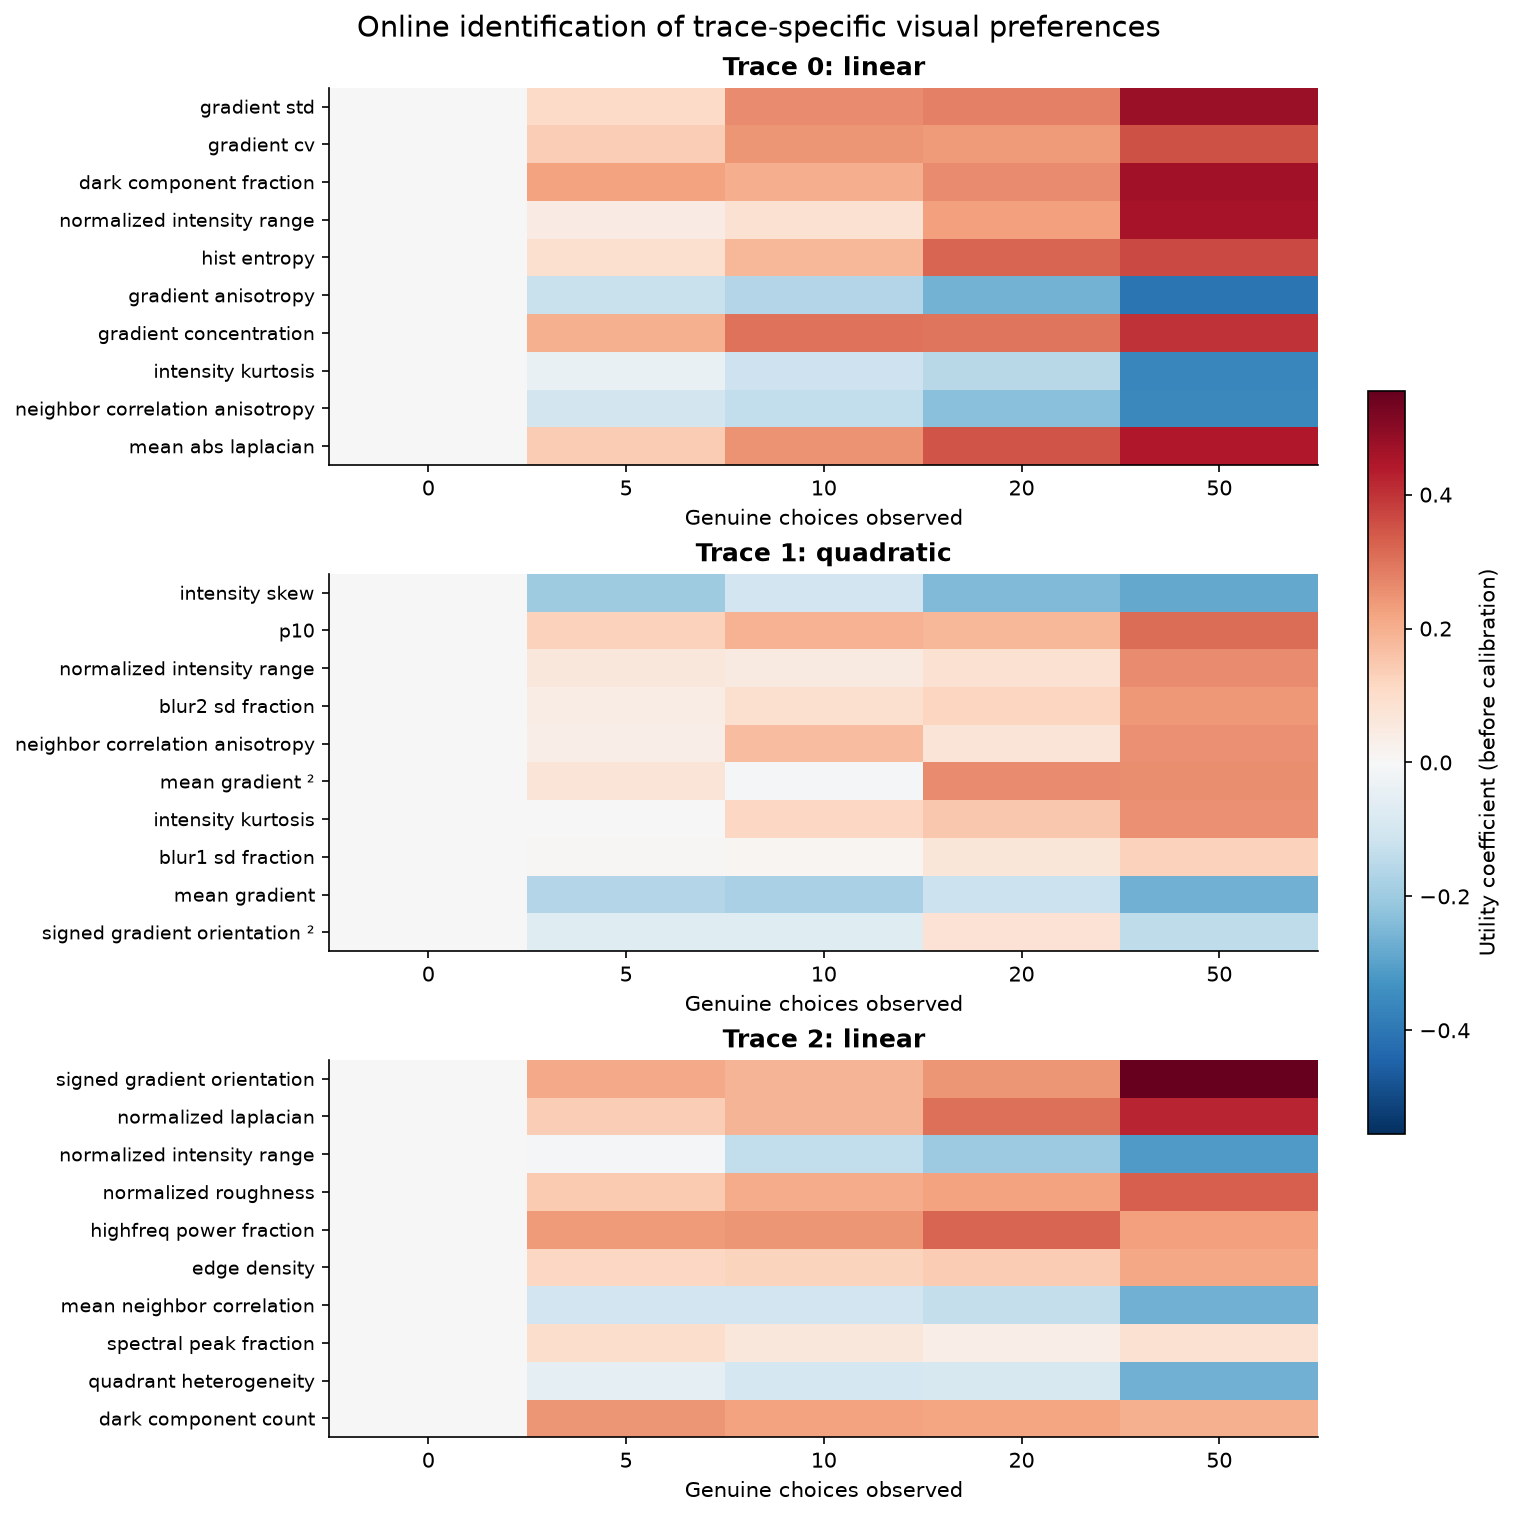

In [ ]:
fig,axes = plt.subplots(3,1,figsize=(10,10),layout='constrained')
snapshot_times = [0,5,10,20,50]
matrices=[]; titles=[]
for i,recipe in enumerate(FROZEN_RECIPES):
    ww = quadratic_weights[i] if recipe=='quadratic' else weights[i]
    names = FEATURES + [name+' ²' for name in FEATURES] if recipe=='quadratic' else FEATURES
    selected = np.argsort(np.abs(ww[50:]).mean(axis=0))[-10:][::-1]
    matrices.append((ww[np.array(snapshot_times)][:,selected].T,[names[j].replace('_',' ') for j in selected]))
    titles.append(f'Trace {i}: {recipe}')
limit = max(np.abs(v).max() for v,n in matrices)
for ax,(values,names),title in zip(axes,matrices,titles):
    im=ax.imshow(values,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
    ax.set(xticks=range(5),xticklabels=snapshot_times,yticks=range(10),yticklabels=names,
           xlabel='Genuine choices observed',title=title)
    ax.tick_params(axis='y',labelsize=9)
fig.colorbar(im,ax=list(axes),label='Utility coefficient (before calibration)',shrink=.55)
fig.suptitle('Online identification of trace-specific visual preferences',fontsize=14)
plt.show()

**Interpretation.** The model learns different descriptor combinations in different traces. Earlier visual inspection and coefficient analyses associate trace 0 with boundaries and gradient variation, trace 1 with smoother lower-contrast content, and trace 2 with directional high-frequency structure. The figure exposes the fitted coefficients rather than claiming a unique verbal objective. Many descriptors are correlated; individual weights can compensate for one another, and neither their signs nor their magnitudes identify a causal internal GPT reward.

The strongest scientific evidence is the combination of rapid prefix adaptation, failure of transferred histories on identical offers, weak global transfer, and strong performance with genuine target history. This favors **within-trace preference persistence and online identification by our predictor** over a single fixed visual reward shared across all traces. It does not distinguish persistent latent prompts from genuine internal sequential adaptation by GPT.

### Separate positive controls

The eight supplied simulated traces are not GPT holdouts. In the completed study, the same fixed online linear procedure reached 69.8% mean top-1 overall and 72.5% after 20 observations. Their reward formulas are unavailable and the supplied score field is constant; these results do not imply a shared GPT objective. A deliberately known, synthetic roughness-maximizing policy provides a cleaner recovery check below. No simulated or synthetic label is used in GPT fitting, calibration, or selection.

In [ ]:
# Known reward: select the greatest normalized roughness among current offers.
known_y = z[2,...,12].argmax(axis=1)
known_scores,_,_ = prequential(z[2],known_y)
known_result = evaluate(known_scores[20:],known_y[20:])
assert np.isclose(known_result['top1'],.9)
control_rows = [{'control':'Known roughness maximizer','window':'after 20 observations',**known_result}]
# Optional raw-data replication; skip automatically if the eight files are absent.
REPRODUCE_SIMULATED = False
if REPRODUCE_SIMULATED:
    for i in range(8):
        sim_images,sim_y = load_trace(DATA_DIR/f'simulated_decision_trace_{i}.pkl')
        sim_raw = np.array([[describe_patch(p) for p in offered] for offered in sim_images])
        sim_scores,_,_ = prequential(normalize(sim_raw),sim_y)
        control_rows.append({'control':f'Provided simulated {i}','window':'after 20 observations',
                              **evaluate(sim_scores[20:],sim_y[20:])})
pd.DataFrame(control_rows).round(3)

,control,window,top1,top3,nll,steps
0,Known roughness maximizer,after 20 observations,0.9,1.0,0.426,80


## 7. Limitations and scientific interpretation

- **Small, dependent sample:** three traces, two distinct offered-set sequences, one scan; decisions within a trace are not independent replicates.
- **Exploration affects validation:** these traces informed feature and library design. The nested result is an exploratory nested-CV estimate, not an unbiased independent final test. No new untouched GPT data are available.
- **Shared offers and content:** traces 0/1 share every ordered offer set; novelty analyses reduce exact-memorization explanations but do not establish cross-scan generalization.
- **Feedback entitlement unresolved:** the demonstrated challenge interface accepts `reward(patch)`. Genuine earlier GPT choices may not be revealed in the organizers' evaluation. The 36.3% result applies only when that history is available.
- **Autonomous failure:** cold self-fed accuracy is 5.3%. Fixed logged offers cannot establish interactive performance when actions could affect future candidate generation.
- **Probability reliability:** the stateless rule's 3.034 log loss is worse than uniform 2.996. Better ranking need not imply reliable probabilities; the runtime's default temperature is a convenience, not a calibration guarantee.
- **Reward is not identified:** correlated features, latent prompts, and persistent per-trace policies can explain the same patterns. Successful history conditioning does not prove GPT has internal sequential memory, learns during the trace, or optimizes our fitted utility.

The defensible interpretation is behavioral: **past genuine selections reveal useful information about a trace's future visual choices**. Our estimator adapts; the experiments do not establish which internal mechanism produced GPT's preferences.

## 8. Final executable prediction API

All dependencies and helper functions needed by this API are defined above in this notebook. There are no imports from the research repository. Use `reward(patch)` or `score_stateless_candidates(patches)` for the demonstrated patch-scoring contract. Use `ObservedPreferenceModel` only if actual previous choices are provided: **predict first, then call `observe` when a genuine choice arrives**. The token prevents accidental reuse or out-of-order observation; `discard` allows a prediction without adding a training label.

The deployment default is the preserved **linear30, ridge10, zero-prior** recipe, whose fixed explored accuracy is 37.0%. `quadratic=True` reproduces the 60-coefficient alternative. The 36.3% benchmark evaluates a nested selection procedure, not a single trace-ID-dependent deployment model. Representation and calibration must be selected on training traces before predicting an unknown target; no universal feedback entitlement or independently validated deployment recipe is claimed. Default inverse temperature 1.0 is uncalibrated; the displayed nested log loss uses training-only fold calibration above.

In [ ]:
def reward(patch):
    """Pure scalar patch reward: high-frequency Fourier-power fraction.

    Accepts only a finite 2-D image; has no access to labels, state, or trace IDs.
    """
    p = np.asarray(patch)
    if p.ndim != 2 or min(p.shape) < 2 or not np.isfinite(p).all():
        raise ValueError('Expected a finite 2-D image with both dimensions >=2.')
    return float(patch_features(p)[11])

def score_stateless_candidates(patches,inverse_temperature=1.0):
    """Rank exactly 20 current patches, with no decision-history updates.

    Candidate-relative probabilities are optional scores, not calibrated claims
    unless inverse_temperature was fitted using permitted training data.
    """
    if len(patches) != 20:
        raise ValueError('Expected exactly 20 candidates.')
    if not np.isfinite(inverse_temperature) or inverse_temperature <= 0:
        raise ValueError('Inverse temperature must be finite and positive.')
    values = np.array([reward(p) for p in patches])
    scores = np.clip((values-values.mean())/(values.std()+EPS),-4,4)
    order = np.argsort(-scores,kind='stable')
    return {'selected_candidate':int(order[0]),'top3':order[:3].tolist(),
            'rewards':values,'scores':scores,
            'probabilities':softmax(inverse_temperature*scores),
            'observed_history_length':0}

class ObservedPreferenceModel:
    """Regularized online preference recovery with explicit feedback boundaries.

    predict(patches): current images only, returns prediction and observation token.
    observe(token, actual_index): append this observed decision AFTER prediction.
    discard(token): clear pending prediction without inventing a training label.

    Reset by constructing a new instance for every independent target trace.
    """
    def __init__(self,quadratic=False,strength=10.0,inverse_temperature=1.0):
        if not np.isfinite(strength) or strength <= 0:
            raise ValueError('Ridge strength must be finite and positive.')
        if not np.isfinite(inverse_temperature) or inverse_temperature <= 0:
            raise ValueError('Inverse temperature must be finite and positive.')
        self.quadratic = bool(quadratic)
        self.strength = float(strength)
        self.inverse_temperature = float(inverse_temperature)
        self.feature_names = FEATURES + [n+' ²' for n in FEATURES] if self.quadratic else list(FEATURES)
        self.weights = np.zeros(len(self.feature_names))
        self._x, self._y, self._pending = [], [], None

    def predict(self,patches):
        if self._pending is not None:
            raise RuntimeError('Observe or discard the pending prediction first.')
        if len(patches) != 20:
            raise ValueError('Expected exactly 20 candidates.')
        current_raw = np.array([describe_patch(p) for p in patches])
        current = representation(normalize(current_raw[None]),self.quadratic)[0]
        n = len(self._y)
        if n:
            self.weights = fit(np.asarray(self._x),np.asarray(self._y,dtype=int),
                               self.strength,self.weights)
        scores = current @ self.weights
        order = np.argsort(-scores,kind='stable')
        token = hashlib.sha256(current.tobytes()+str(n).encode()).hexdigest()
        self._pending = (token,current.copy())
        return {'selected_candidate':int(order[0]),'top3':order[:3].tolist(),
                'scores':scores.copy(),'probabilities':softmax(self.inverse_temperature*scores),
                'observed_history_length':n,'cold_start_uniform':n==0,'token':token,
                'feature_contributions':current[order[0]]*self.weights}

    def observe(self,token,actual_selected_candidate):
        """Add a genuine revealed choice. Never call before predict for this set."""
        if self._pending is None or token != self._pending[0]:
            raise ValueError('Token does not match the pending prediction.')
        k = actual_selected_candidate
        if isinstance(k,(bool,np.bool_)) or not isinstance(k,(int,np.integer)) or not 0 <= k < 20:
            raise ValueError('Selected candidate must be an integer from 0 through 19.')
        self._x.append(self._pending[1]); self._y.append(int(k)); self._pending = None

    def discard(self,token):
        if self._pending is None or token != self._pending[0]:
            raise ValueError('Token does not match the pending prediction.')
        self._pending = None

def predict_with_history(patches,state):
    """Convenience wrapper: does not accept the current selected index."""
    return state.predict(patches)

def update_preference_state(state,token,observed_choice):
    """Call only once the actual choice has been observed."""
    state.observe(token,observed_choice)

In [ ]:
# Legitimate example: observe decisions 0..9, then predict decision 10.
# Its chosen index is not read until AFTER this demonstration prediction.
example_state = ObservedPreferenceModel()
for t in range(10):
    previous_prediction = predict_with_history(images[0,t],example_state)
    update_preference_state(example_state,previous_prediction['token'],int(y[0,t]))
next_prediction = predict_with_history(images[0,10],example_state)
static_prediction = score_stateless_candidates(images[0,10])
assert next_prediction['observed_history_length'] == 10
example_table = pd.DataFrame({'candidate':np.arange(20),
                              'stateless reward':static_prediction['rewards'],
                              'history utility':next_prediction['scores'],
                              'history probability':next_prediction['probabilities']})
example_state.discard(next_prediction['token'])  # Do not invent an observation.
example_table.sort_values('history utility',ascending=False).head(5).round(4)

,candidate,stateless reward,history utility,history probability
8,8,0.1156,1.1423,0.1220
7,7,0.1277,1.0418,0.1104
14,14,0.0749,0.7731,0.0844
15,15,0.1959,0.7436,0.0819
16,16,0.0498,0.5816,0.0697


**API example.** The table displays the five highest-utility candidates among all 20 current offers after exactly ten legitimate prior observations. The current correct answer is deliberately not shown or used. Passing the predicted index to `observe` instead of the genuine choice explicitly requests self-fed replay, whose much lower performance is reported separately.

### Inline validation of the submitted implementation

The checks below perturb current/future labels, permute candidate positions, exercise token/update guards, and replay **the actual public class** under the frozen fold configurations. It must reproduce all 300 retained score vectors and 109 correct choices. This checks the delivered inference code rather than only a separate evaluation helper.

In [ ]:
# 1. Current/future outcomes and later offers cannot change an earlier prediction.
base,_,_ = prequential(z[0,:22],y[0,:22])
changed_y = y[0,:22].copy(); changed_y[10:] = (changed_y[10:]+7)%20
changed_x = z[0,:22].copy(); changed_x[11:] *= -2
altered,_,_ = prequential(changed_x,changed_y)
np.testing.assert_array_equal(base[:11],altered[:11])

# 2. Prediction inputs are images only; permutation changes order, not utility.
original = images[0,10].copy()
state_a = ObservedPreferenceModel()
for t in range(6):
    r = state_a.predict(images[0,t]); state_a.observe(r['token'],int(y[0,t]))
state_b = copy.deepcopy(state_a)
perm = np.random.default_rng(5).permutation(20)
a = state_a.predict(original); b = state_b.predict(original[perm])
np.testing.assert_allclose(a['scores'][perm],b['scores'],atol=1e-8)
np.testing.assert_array_equal(images[0,10],original)
np.testing.assert_allclose(sum(a['probabilities']),1)
assert perm[b['selected_candidate']] == a['selected_candidate']
try:
    state_a.predict(original)
    raise AssertionError('Missing pending-observation guard.')
except RuntimeError:
    pass
try:
    state_a.observe('wrong-token',0)
    raise AssertionError('Missing token guard.')
except ValueError:
    pass
state_a.discard(a['token']); state_b.discard(b['token'])

# 3. Replay the inline class using training-selected representations/calibration.
api_scores = []
for i,recipe in enumerate(FROZEN_RECIPES):
    state = ObservedPreferenceModel(quadratic=recipe=='quadratic',
                    inverse_temperature=calibration_rows[i]['online beta'])
    scores = []
    for t in range(100):
        r = state.predict(images[i,t])  # No y[i,t] in the call.
        assert r['observed_history_length'] == t
        scores.append(np.log(r['probabilities']))
        state.observe(r['token'],int(y[i,t]))  # Reveal only after prediction.
    api_scores.append(scores)
api_scores = np.asarray(api_scores)
# Utilities and log probabilities differ only by one normalizing constant per set.
np.testing.assert_allclose(api_scores,retained-logsumexp(retained,axis=-1,keepdims=True),atol=1e-8)
assert int((api_scores.argmax(axis=-1)==y).sum()) == 109
validation = pd.DataFrame({'check':['Raw-data metric regression','Future-label perturbation',
                                    'Candidate permutation','Prediction/update ordering',
                                    'Inline class reproduces retained predictions'],
                           'status':['PASS']*5})
validation

,check,status
0,Raw-data metric regression,PASS
1,Future-label perturbation,PASS
2,Candidate permutation,PASS
3,Prediction/update ordering,PASS
4,Inline class reproduces retained predictions,PASS


## 9. Conclusion

We attempted to infer a compact visual utility behind GPT's AFM choices. Fixed image reward explains some ranking behavior, but the decisive information is **which visual content a particular trace previously selected**. A regularized preference estimator turns that feedback into 36.3% top-1 and 62.7% top-3 under the retained exploratory nested protocol, improving top-1 by 19.7 percentage points over the original similarity rule. A ten-choice prefix already captures much of the available signal.

Matched-offer history swaps, past-only randomization, novelty checks, and weak global transfer together support **trace-specific visual preference persistence**. They do not reveal GPT's true internal reward or prove sequential learning inside GPT. Cold self-fed failure shows that genuine observations carry information that the predictor cannot manufacture from its own guesses.

The retained benchmark remains the final scientific result; the expanded challenger is not promoted. The unresolved questions are transfer to independent traces and scans, the cause of between-trace preferences, and whether observed feedback will be available in final evaluation. The notebook supplies both the demonstrated stateless interface and a clearly conditional history-aware interface, with their performance kept separate.

---

**Submission:** `AFM_FINAL.ipynb` only. Raw organizer traces are needed to rerun; no other development or research artifact is required to inspect the methods and saved results.